<a href="https://colab.research.google.com/github/yasminasouki/DataAnalysis/blob/dev/04_gradcam.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import numpy as np, pandas as pd, tensorflow as tf, os
from tensorflow import keras
from tensorflow.keras.applications.densenet import preprocess_input

PROJ = '/content/drive/MyDrive/pneumonia-project'
IN   = f'{PROJ}/results_03'
OUT  = f'{PROJ}/results_04'
os.makedirs(f'{OUT}/figures', exist_ok=True)

# trained model from notebook 03
model = keras.models.load_model(f'{IN}/densenet121_best.keras')

# images + split (same order)
split = pd.read_csv(f'{PROJ}/split.csv')
images = np.load(f'{PROJ}/images_224.npz', allow_pickle=True)['images']
te = split['split'].values == 'test'
X_te = images[te]

# Joy's test predictions (same order as X_te)
pred = pd.read_csv(f'{IN}/test_predictions.csv')

print("Test images:", X_te.shape, "| predictions:", pred.shape)
print(pred.columns.tolist())
print([l.name for l in model.layers])

Mounted at /content/drive
Test images: (1869, 224, 224) | predictions: (1869, 13)
['patientId', 'age', 'sex', 'view', 'height_px', 'width_px', 'class', 'nih_image', 'real_patient_id', 'split', 'target', 'prob_base', 'prob_cnn']
['input_layer_2', 'densenet121', 'global_average_pooling2d', 'dropout', 'dense']


In [2]:
def prep(imgs):
    x = imgs.astype('float32')[..., None]
    x = np.repeat(x, 3, axis=-1)          # gray -> 3 channels, like in notebook 03
    return preprocess_input(x)

check = model.predict(prep(X_te[:8]), verbose=0).ravel()
print("Now:     ", np.round(check, 3))
print("Notebook 03:", np.round(pred['prob_cnn'].values[:8], 3))

Now:      [0.966 0.713 0.694 0.818 0.896 0.5   0.899 0.821]
Notebook 03: [0.966 0.713 0.694 0.818 0.896 0.5   0.899 0.821]


In [3]:
base  = model.get_layer('densenet121')
gap   = model.layers[2]     # global average pooling
dense = model.layers[-1]    # final layer -> pneumonia probability

def gradcam(img):
    x = tf.convert_to_tensor(prep(img[None]))
    with tf.GradientTape() as tape:
        feat = base(x, training=False)        # 7x7 grid of 1024 feature maps
        tape.watch(feat)
        prob = dense(gap(feat))               # pneumonia probability
    grads = tape.gradient(prob, feat)[0]      # how much each map pushes toward "pneumonia"
    weights = tf.reduce_mean(grads, axis=(0, 1))
    cam = tf.nn.relu(tf.reduce_sum(feat[0] * weights, axis=-1))
    cam = cam / (tf.reduce_max(cam) + 1e-8)   # scale to 0–1
    cam = tf.image.resize(cam[..., None], (224, 224)).numpy()[..., 0]
    return cam, float(prob[0, 0])

cam, p = gradcam(X_te[0])
print("Heatmap:", cam.shape, "| prob:", round(p, 3),
      "| notebook 03:", round(pred['prob_cnn'][0], 3))

Heatmap: (224, 224) | prob: 0.966 | notebook 03: 0.966


In [4]:
pred['pred'] = (pred['prob_cnn'] >= 0.5).astype(int)

def group(r):
    if r.target == 1 and r.pred == 1: return 'Correct pneumonia'
    if r.target == 1:                 return 'Missed pneumonia'
    if r.pred == 1:                   return 'False alarm'
    return 'Correct no pneumonia'

pred['group'] = pred.apply(group, axis=1)
print(pd.crosstab(pred['group'], pred['view'], margins=True))

groups = ['Correct pneumonia', 'Missed pneumonia', 'False alarm', 'Correct no pneumonia']
picks = []
for g in groups:
    for v in ['AP', 'PA']:
        picks += pred[(pred.group == g) & (pred.view == v)].sample(2, random_state=42).index.tolist()
print("Picked:", len(picks), "X-rays")

view                   AP    PA   All
group                                
Correct no pneumonia  154   864  1018
Correct pneumonia     352    66   418
False alarm           202    57   259
Missed pneumonia       45   129   174
All                   753  1116  1869
Picked: 16 X-rays


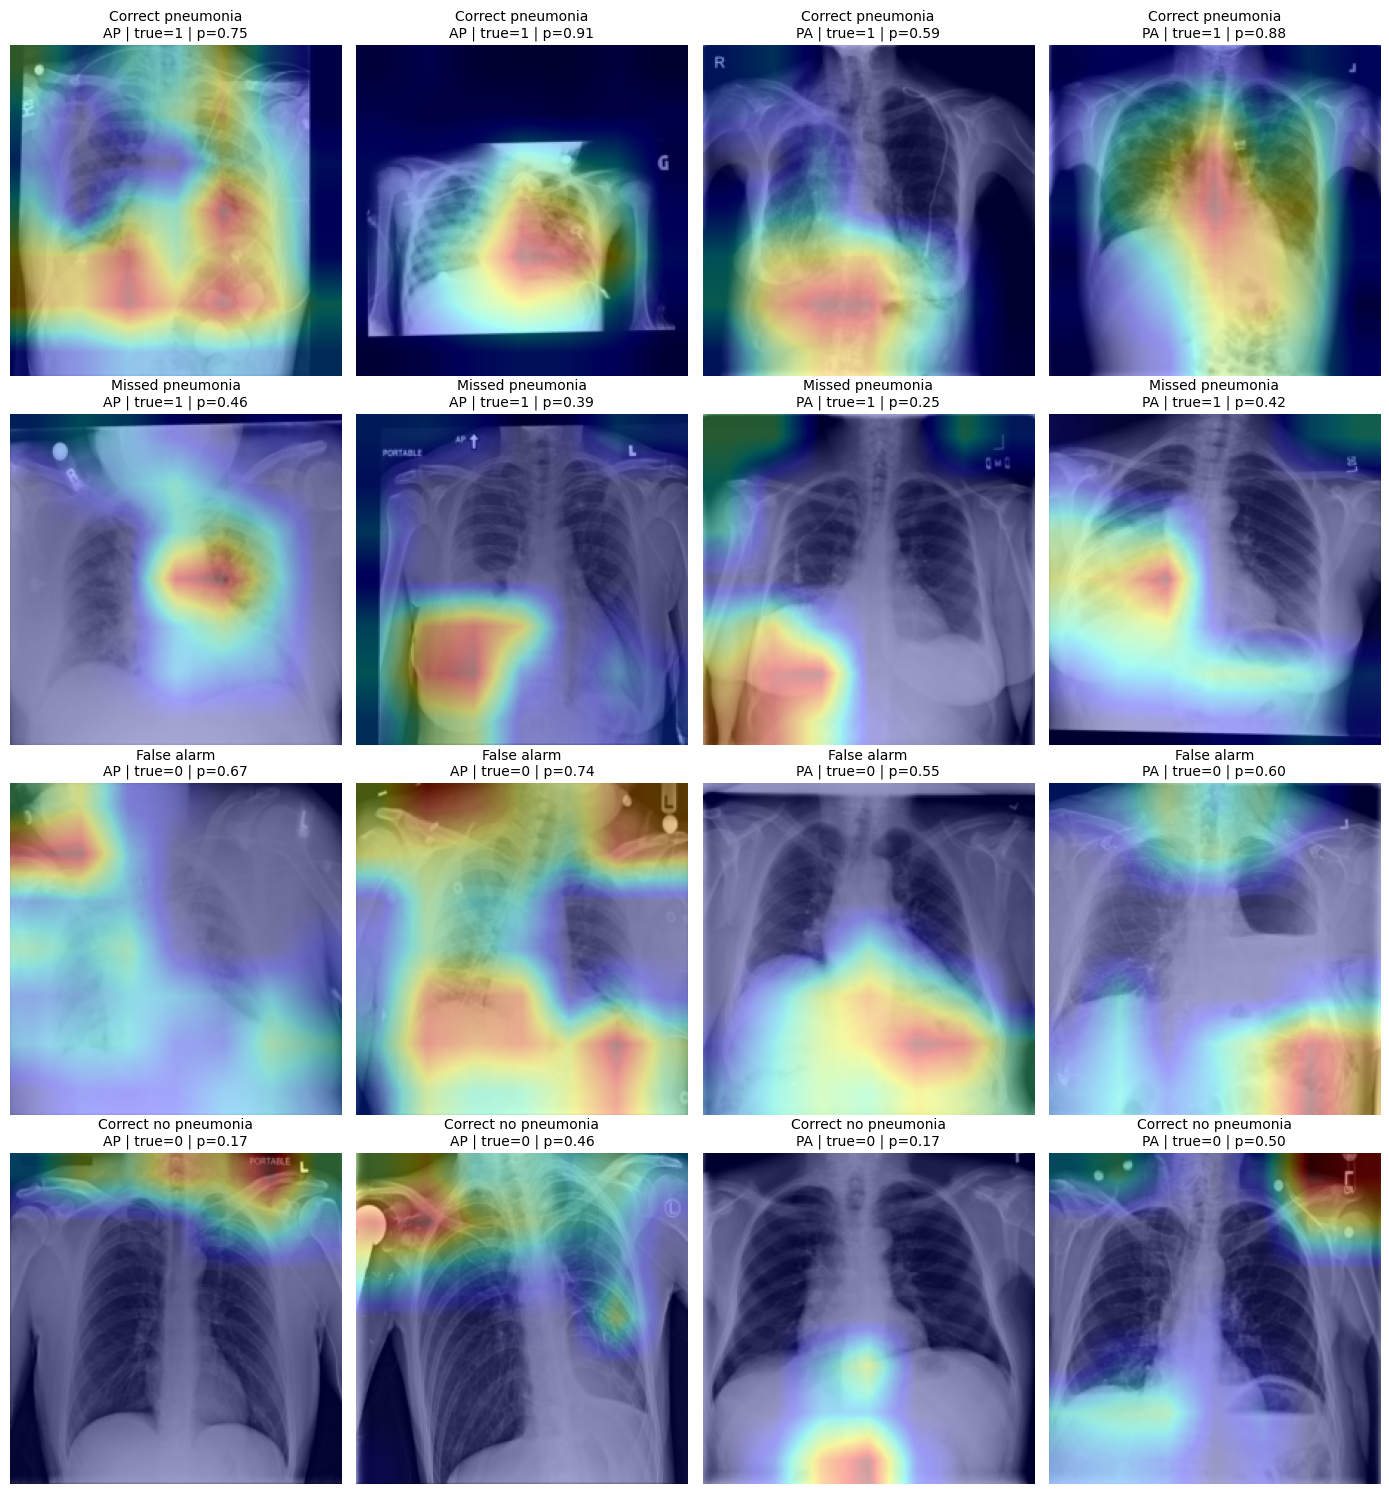

In [6]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(4, 4, figsize=(14, 15))
for ax, i in zip(axes.ravel(), picks):
    cam, p = gradcam(X_te[i])
    r = pred.loc[i]
    ax.imshow(X_te[i], cmap='gray')
    ax.imshow(cam, cmap='jet', alpha=0.35)
    ax.set_title(f"{r['group']}\n{r['view']} | true={r['target']} | p={p:.2f}", fontsize=10)
    ax.axis('off')
plt.tight_layout()
plt.savefig(f'{OUT}/figures/04_gradcam_examples.png', dpi=300, bbox_inches='tight')
plt.show()

In [7]:
import glob
lab_path = glob.glob(f'{PROJ}/*train_labels*.csv')[0]
boxes = pd.read_csv(lab_path).dropna(subset=['x'])
print("Box file:", lab_path.split('/')[-1], "| boxes:", len(boxes))

S = 224 / 1024                                  # boxes are in 1024-px coordinates
edge = np.ones((224, 224), bool); edge[22:-22, 22:-22] = False   # outer 10% frame

rows = []
for i in range(len(X_te)):
    cam, p = gradcam(X_te[i])
    r = pred.loc[i]
    row = {'i': i, 'view': r['view'], 'group': r['group'],
           'edge_heat': cam[edge].sum() / (cam.sum() + 1e-8)}
    if r['target'] == 1:
        mask = np.zeros((224, 224), bool)
        for _, b in boxes[boxes.patientId == r['patientId']].iterrows():
            x0, y0 = int(b.x * S), int(b.y * S)
            x1, y1 = int((b.x + b.width) * S) + 1, int((b.y + b.height) * S) + 1
            mask[y0:y1, x0:x1] = True
        yy, xx = np.unravel_index(cam.argmax(), cam.shape)
        row['peak_in_box'] = bool(mask[yy, xx])
        row['box_area'] = mask.mean()
    rows.append(row)
    if i % 300 == 0: print(i, "done")

cams = pd.DataFrame(rows)
cams.to_csv(f'{OUT}/gradcam_stats.csv', index=False)

print("\nPointing game (pneumonia X-rays): is the hottest point inside a radiologist box?")
pos = cams.dropna(subset=['peak_in_box'])
print(pos.groupby(['view', 'group'])['peak_in_box'].agg(['mean', 'count']).round(3))
print("Average box area (share of image):", round(pos['box_area'].mean(), 3))

print("\nShare of heat on the outer 10% frame of the image:")
print(cams.groupby(['view', 'group'])['edge_heat'].mean().round(3).unstack())
print("(The frame is", round(edge.mean(), 3), "of the image area.)")

Box file: stage_2_train_labels.csv | boxes: 9555
0 done
300 done
600 done
900 done
1200 done
1500 done
1800 done

Pointing game (pneumonia X-rays): is the hottest point inside a radiologist box?
                            mean  count
view group                             
AP   Correct pneumonia  0.295455    352
     Missed pneumonia   0.155556     45
PA   Correct pneumonia  0.151515     66
     Missed pneumonia   0.116279    129
Average box area (share of image): 0.104

Share of heat on the outer 10% frame of the image:
group  Correct no pneumonia  Correct pneumonia  False alarm  Missed pneumonia
view                                                                         
AP                    0.539              0.253        0.295             0.456
PA                    0.610              0.251        0.279             0.462
(The frame is 0.354 of the image area.)


In [8]:
print(pos.groupby('view')['box_area'].mean().round(3))

view
AP    0.119
PA    0.074
Name: box_area, dtype: float64
